# 05 · Compare prediction and capacity

Compare all five models on the same held-out sequences within each seed. Preserve negative results.

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Saved-run findings

These saved outputs use **experiment**, 3 seeds, and 40 epochs.

Against dense_active, learned MoE mean paired MSE difference is +0.000335 (sample SD 0.000146); mean within-seed relative change +3.03%. MoE has lower error in 0/3 seeds.

Against dense_total, learned MoE mean paired MSE difference is +0.000399 (sample SD 0.000106); mean within-seed relative change +3.61%. MoE has lower error in 0/3 seeds.

This is an initial controlled benchmark, not a general claim. **Rerunning without `TWILIGHT_CONFIG` uses the smoke preset.** This saved summary is regenerated with `scripts/summarize_results.py`; after changing settings, use the new computed tables below as the current results.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Load complete results

Run notebooks 03 and 04 first. The table uses original state units squared.

In [2]:
from twilight_moe.experiment import load_metrics
from twilight_moe.models import MODEL_NAMES
results = load_metrics(cfg)
results = results[results.model.isin(MODEL_NAMES)]
assert len(results) == len(MODEL_NAMES)*len(cfg['seeds']), 'Train all five models for all seeds first'
display(results[['model', 'seed', 'test_mse', 'switch_mse', 'rollout_mean_mse',
                 'total_parameters', 'active_parameters', 'trainable_parameters']].round(6))

,model,seed,test_mse,switch_mse,rollout_mean_mse,total_parameters,active_parameters,trainable_parameters
0,dense_active,7,0.011182,0.071878,0.056849,5419,5419,5419
1,dense_total,7,0.011116,0.071654,0.056188,7564,7564,7564
2,moe,7,0.011591,0.070045,0.056010,7599,5355,7599
3,random,7,0.011750,0.070172,0.052335,6828,4584,6732
4,oracle,7,0.006621,0.006541,0.051574,6732,2244,6732
5,dense_active,17,0.011312,0.074502,0.057297,5419,5419,5419
6,dense_total,17,0.011202,0.074870,0.057144,7564,7564,7564
7,moe,17,0.011479,0.073397,0.059854,7599,5355,7599
8,random,17,0.011870,0.073095,0.061657,6828,4584,6732
9,oracle,17,0.006709,0.006888,0.056069,6732,2244,6732


## Plot one-step error

Bars show seed means. Points show individual seeds, not confidence intervals.

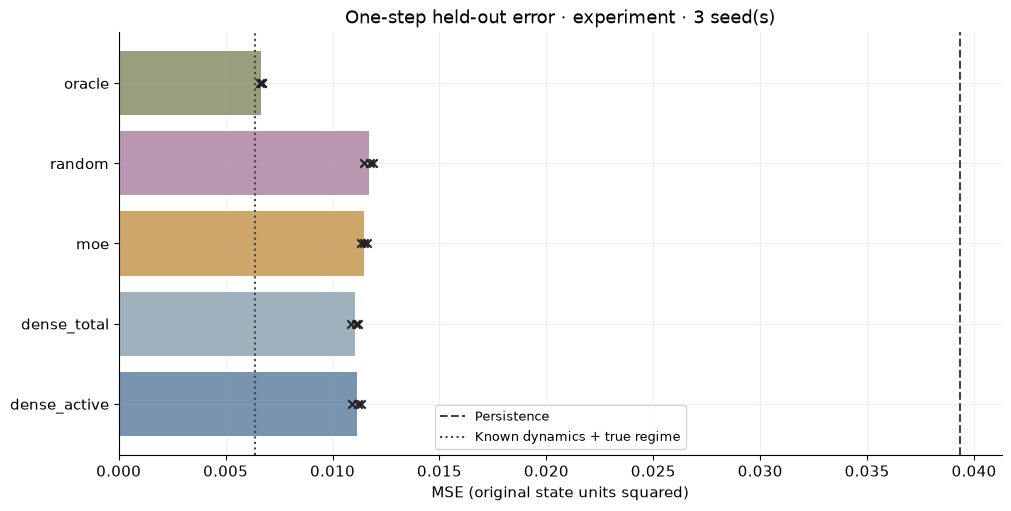

In [3]:
names = list(MODEL_NAMES)
means = results.groupby('model')['test_mse'].mean().reindex(names)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(names, means, color=[COLORS[n] for n in names], alpha=.65)
for i, name in enumerate(names):
    ax.scatter(results.loc[results.model == name, 'test_mse'],
               np.full(sum(results.model == name), i), color='#222222', marker='x', zorder=3)
ax.axvline(results['persistence_mse'].mean(), color='#444444', linestyle='--', label='Persistence')
ax.axvline(results['known_dynamics_mse'].mean(), color='#444444', linestyle=':', label='Known dynamics + true regime')
ax.set(title=f'One-step held-out error · {cfg["name"]} · {len(cfg["seeds"])} seed(s)',
       xlabel='MSE (original state units squared)', xlim=(0, None))
ax.legend(fontsize=9)
save_figure(fig, cfg, 'one_step_comparison')
plt.show()

## Calculate paired differences

Negative MoE-minus-dense differences favor MoE. Seeds vary both data and initialization.

In [4]:
paired = results.pivot(index='seed', columns='model', values='test_mse')
differences = pd.DataFrame({name: paired['moe']-paired[name] for name in ['dense_active', 'dense_total']})
display(differences.rename(columns=lambda n: 'MoE minus ' + n).round(6))
print('Per-seed mean differences:', differences.mean().to_dict())
if len(differences) == 1:
    print('One smoke seed: no uncertainty estimate or general performance conclusion.')
else:
    print('Sample SD across paired seeds:', differences.std(ddof=1).to_dict())

,MoE minus dense_active,MoE minus dense_total
seed,,
7,0.000410,0.000475
17,0.000167,0.000277
27,0.000429,0.000444


Per-seed mean differences: {'dense_active': 0.0003353869542479515, 'dense_total': 0.00039868801832199097}
Sample SD across paired seeds: {'dense_active': 0.00014609459475412387, 'dense_total': 0.00010648420394887044}


## Check capacity matching

Report the realized mismatch; active parameter counts do not measure actual runtime.

In [5]:
capacity = results.groupby('model')[['total_parameters', 'active_parameters']].first()
display(capacity)
for dense, field in [('dense_active', 'active_parameters'), ('dense_total', 'total_parameters')]:
    mismatch = (capacity.loc[dense, field]/capacity.loc['moe', field]-1)*100
    print(f'{dense} mismatch: {mismatch:+.2f}%')

,total_parameters,active_parameters
model,,
dense_active,5419,5419
dense_total,7564,7564
moe,7599,5355
oracle,6732,2244
random,6828,4584


dense_active mismatch: +1.20%
dense_total mismatch: -0.46%


## Takeaways

Read the actual paired differences before making a claim. The smoke run verifies mechanics. Even the full preset is an initial controlled benchmark; broader seeds and equal tuning budgets are needed.